# BIOT 6900 · Module 6, Part 3 — Graded Assignment: PRS Portability on Real Data

You now run the full workflow yourself, on **real 1000 Genomes genotypes** with a **published Alzheimer's score from the PGS Catalog** (PGS000334, which includes APOE, connecting to your Part I work): harmonize the alleles, compute the PRS, and evaluate discrimination, calibration, and the portability problem across ancestry groups. Then you write it up.

Complete every **# TODO**, then **Kernel → Restart & Run All**.


### Data (provided on Canvas)

Download **`data.zip`** from Canvas and unzip it next to the notebook, so you have a `data/` folder with the four CSV files and `README.md`. Keep the folder named `data`, and read the README (it documents the cohort, the simulated phenotype, and the APOE caveat).

| File | Columns | Notes |
|---|---|---|
| `genotypes.csv` | one column per variant, rows = people | dosages 0/1/2, **counting the ALT allele** |
| `variants.csv` | `variant`, `ref`, `alt` | the REF/ALT nucleotides, same build as the genotypes |
| `score.csv` | `variant`, `effect_allele`, `other_allele`, `weight` | the provided Alzheimer's score (PGS000334); alleles as published |
| `meta.csv` | `ancestry`, `age`, `phenotype` | ancestry = EUR/AFR/EAS/SAS/AMR; phenotype is 1 = case |

> **This is a graded run, so it must use real data.** The loader **stops with an error** unless all four files are present. A `USE_DEMO` flag exists only so you can prototype on synthetic data while you wait for files; **it must be `False` in your submission.**

> ⚠️ **The phenotype is simulated.** 1000 Genomes has no disease labels, so `phenotype` is simulated. The PRS and its distribution across ancestries are computed on real inputs; AUC and calibration use the simulated label and are illustrative. Say this in your write-up.

> **APOE caveat.** In this simulated cohort the LD proxy for APOE ε4 is almost absent in African-ancestry samples, so ε4 appears to have little effect in AFR here and the score runs near chance there. That is an artifact of the simulation design, **not real biology**: ε4 is a risk allele across ancestries. Keep that distinction in your write-up.

> **Proof of real data.** Section 2 prints a fingerprint (file checksums, counts). **Paste it into your report** so the grader can confirm you ran real data.


## 0. Setup

In [1]:
import os, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

NU_RED, NU_COOL, NU_GREY = "#C8102E", "#1E2028", "#6E7178"
POP_COLORS = {"EUR":"#1E2028","AFR":"#C8102E","EAS":"#6E7178","SAS":"#A4804A","AMR":"#9AA0A6"}
rng = np.random.default_rng(6900)

USE_DEMO = False     # <-- prototyping only. MUST be False for your graded submission.

## 1. Load the data  *(provided, do not edit)*

Strict loader: with `USE_DEMO = False` it requires all four real files and refuses to run otherwise. The demo path is clearly labelled and is never acceptable for grading.

In [2]:
BASES = np.array(list("ACGT"))
def _make_demo_cohort(seed=6900):
    r = np.random.default_rng(seed)
    pops = {"EUR":(600,0.92,0.05,0.14),"AFR":(600,0.40,0.15,0.22),"EAS":(500,0.58,0.12,0.09),
            "SAS":(500,0.66,0.09,0.09),"AMR":(500,0.55,0.07,0.11)}   # n, tag-rho, drift, APOE freq
    M = 80
    b = r.normal(0, 0.15, M); b[0] = 1.3
    w_true = b * 0.92
    base = r.uniform(0.15, 0.5, M)
    Gt, Gc, anc, ages = [], [], [], []
    for pop,(n,rho,drift,apoe) in pops.items():
        f = np.clip(base + r.normal(0,drift,M), 0.03, 0.97); f[0] = apoe; thr = norm.ppf(f)
        gc = np.zeros((n,M)); gt = np.zeros((n,M))
        for _ in range(2):
            L = r.normal(size=(n,M)); Z = r.normal(size=(n,M))
            gc += (L<thr); gt += ((rho*L + np.sqrt(1-rho**2)*Z) < thr)
        Gt.append(gt); Gc.append(gc); anc += [pop]*n; ages.append(r.normal(60,8,n))
    Gt = np.vstack(Gt); Gc = np.vstack(Gc); anc = np.array(anc); age = np.concatenate(ages)
    lin = Gc @ b + 0.03*(age-60); b0 = np.log(0.30/0.70) - lin.mean()
    y = (r.uniform(size=len(lin)) < 1/(1+np.exp(-(b0+lin)))).astype(int)
    variants = [f"rs_tag_{i:03d}" for i in range(M)]
    # real nucleotides: pick ref != alt; dosages count ALT
    ref = r.choice(BASES, M); alt = np.array([r.choice(BASES[BASES!=ref[i]]) for i in range(M)])
    geno = pd.DataFrame(Gt, columns=variants)
    vtab = pd.DataFrame({"variant":variants, "ref":ref, "alt":alt})
    # 25% of rows report the REF allele as effect allele, with the weight's sign reversed
    report_ref = r.random(M) < 0.25
    eff = np.where(report_ref, ref, alt); oth = np.where(report_ref, alt, ref)
    wrep = np.where(report_ref, -w_true, w_true)
    score = pd.DataFrame({"variant":variants, "effect_allele":eff, "other_allele":oth, "weight":wrep})
    meta  = pd.DataFrame({"ancestry":anc, "age":age, "phenotype":y})
    return geno, vtab, score, meta

REAL_FILES = ["genotypes.csv","variants.csv","score.csv","meta.csv"]
def _sha8(path):
    h = hashlib.sha256(open(path,"rb").read()).hexdigest()[:8]
    return h

def load_data(path="data"):
    present = [f for f in REAL_FILES if os.path.exists(os.path.join(path,f))]
    if not USE_DEMO:
        missing = [f for f in REAL_FILES if f not in present]
        if missing:
            raise FileNotFoundError(
                "GRADED RUN requires all four files in ./%s/ . Missing: %s .  "
                "Set USE_DEMO=True ONLY to prototype on synthetic data; it must be False for submission."
                % (path, ", ".join(missing)))
        geno=pd.read_csv(os.path.join(path,"genotypes.csv"))
        vtab=pd.read_csv(os.path.join(path,"variants.csv"))
        score=pd.read_csv(os.path.join(path,"score.csv"))
        meta=pd.read_csv(os.path.join(path,"meta.csv"))
        info={"source":"REAL","hashes":{f:_sha8(os.path.join(path,f)) for f in REAL_FILES}}
        print("="*64); print("  RUNNING ON REAL DATA"); print("="*64)
    else:
        print("="*64); print("  USE_DEMO=True  ->  SYNTHETIC demo cohort  (NOT FOR GRADING)"); print("="*64)
        geno,vtab,score,meta=_make_demo_cohort(); info={"source":"DEMO","hashes":None}
    return geno, vtab, score, meta, info

geno, variants, score, meta, info = load_data()

  RUNNING ON REAL DATA


## 2. Proof of real data  *(paste this block into your report)*

In [3]:
print("source      :", info["source"])
print("people      :", len(meta))
print("score size  :", len(score), "variants")
print("by ancestry :", dict(meta["ancestry"].value_counts()))
if info["source"] == "REAL":
    for f,h in info["hashes"].items():
        print(f"  {f}: sha256 {h}")
else:
    print("  DEMO cohort - not acceptable for your graded submission")

source      : REAL
people      : 2336
score size  : 22 variants
by ancestry : {'AFR': np.int64(500), 'EAS': np.int64(500), 'EUR': np.int64(500), 'SAS': np.int64(489), 'AMR': np.int64(347)}
  genotypes.csv: sha256 9cf41a1f
  variants.csv: sha256 f7a87d3f
  score.csv: sha256 7f80e8ff
  meta.csv: sha256 6cc55b6e


## 3.1 Harmonize alleles: keep / flip / drop  *(TODO)*

For each variant, compare the score's `effect_allele` with that variant's REF and ALT:
- equals **ALT** -> keep the dosage and weight as is,
- equals **REF** -> flip the dosage (`2 - dosage`),
- equals **neither** -> drop the variant.

Report how many you used, flipped, and dropped.

In [4]:
shared = [v for v in score["variant"] if v in geno.columns]
G = geno[shared].to_numpy(dtype=float).copy()
s = score.set_index("variant").loc[shared]
v = variants.set_index("variant").loc[shared]
eff = s["effect_allele"].to_numpy()
ref = v["ref"].to_numpy(); alt = v["alt"].to_numpy()
w = s["weight"].to_numpy()

# TODO: build three boolean masks over the variants
keep = eff == alt                      # TODO: effect allele == ALT
flip = eff == ref                      # TODO: effect allele == REF
drop = ~(keep | flip)                  # TODO: neither

# TODO: flip the dosages of the `flip` variants (hint: G[:, flip] = 2 - G[:, flip])
G[:, flip] = 2 - G[:, flip]
# TODO: then remove the `drop` variants from G and w
G = G[:, ~drop]
w = w[~drop]

print(f"used {int((keep|flip).sum())}  flipped {int(flip.sum())}  dropped {int(drop.sum())}")
not_found = len(score) - len(shared)
print(f"not found in genotype panel: {not_found}")

used 22  flipped 13  dropped 0
not found in genotype panel: 0


## 3.2 Compute the PRS  *(TODO)*

In [5]:
# TODO: PRS = dosages times weights, summed per person (hint: G @ w)
prs = G @ w                       # TODO
prs_z = (prs - prs.mean()) / prs.std()
meta["prs"] = prs_z
print("PRS computed for", len(prs_z), "people")

PRS computed for 2336 people


## 3.3 Distribution shift and a single cutoff  *(TODO)*

Plot the PRS distribution per ancestry, then show what one fixed cutoff does: take the whole-cohort top-10% PRS value and report the fraction of each ancestry group above it.

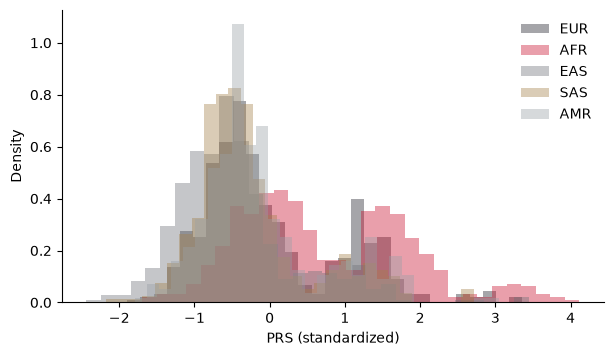

EUR: mean PRS = 0.036, above cutoff = 7.8%
AFR: mean PRS = 0.744, above cutoff = 28.0%
EAS: mean PRS = -0.472, above cutoff = 2.2%
SAS: mean PRS = -0.245, above cutoff = 4.3%
AMR: mean PRS = -0.099, above cutoff = 6.3%


In [6]:
fig, ax = plt.subplots(figsize=(7,3.8))
for pop, c in POP_COLORS.items():
    sub = meta.loc[meta.ancestry==pop, "prs"]
    # TODO: ax.hist(sub, bins=30, density=True, alpha=0.4, color=c, label=pop)
    ax.hist(sub, bins=30, density=True, alpha=0.4, color=c, label=pop)                        # TODO
ax.set_xlabel("PRS (standardized)"); ax.set_ylabel("Density"); ax.legend(frameon=False)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.show()

cutoff = np.quantile(meta["prs"], 0.90)
# TODO: for each ancestry, print mean PRS and the % of that group with prs > cutoff
for pop in POP_COLORS.keys():
    sub = meta.loc[meta.ancestry==pop, "prs"]
    mean_prs = sub.mean()
    pct_above = (sub > cutoff) .mean() * 100
    print(f"{pop}: mean PRS = {mean_prs:.3f}, above cutoff = {pct_above:.1f}%")

## 3.4 Discrimination by ancestry  *(TODO)*

In [7]:
y = meta["phenotype"].to_numpy()
print("Overall AUC:",roc_auc_score(y,meta["prs"]) )      # TODO
for pop in POP_COLORS:          # TODO: AUC within each ancestry group
    m = (meta.ancestry==pop).to_numpy()
    print(f"  {pop}: AUC = {roc_auc_score(y[m], meta['prs'][m]):.3f}")   # TODO

Overall AUC: 0.5985568890226718
  EUR: AUC = 0.672
  AFR: AUC = 0.493
  EAS: AUC = 0.575
  SAS: AUC = 0.611
  AMR: AUC = 0.555


## 3.5 Calibration by ancestry  *(TODO)*

Fit the risk model **in EUR only**, apply it to everyone, and draw one calibration curve per ancestry. A model honest in EUR is often not honest elsewhere. The helper is provided.

In [8]:
def calibration_points(y, p, bins=5):
    edges = np.quantile(p, np.linspace(0,1,bins+1)); edges[-1]+=1e-9
    idx = np.clip(np.digitize(p, edges)-1, 0, bins-1)
    xs, ys = [], []
    for b in range(bins):
        m = idx==b
        if m.sum() > 5: xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

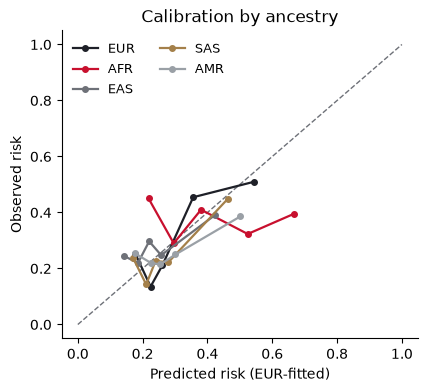

In [9]:
prs_z = meta["prs"].to_numpy(); y = meta["phenotype"].to_numpy()
eur = (meta.ancestry=="EUR").to_numpy()

# TODO: fit LogisticRegression on EUR only (prs_z[eur] -> y[eur]), then predict_proba for everyone
model = LogisticRegression().fit(prs_z[eur].reshape(-1,1), y[eur])                     # TODO
p_hat = model.predict_proba(prs_z.reshape(-1,1))[:,1]                     # TODO

fig, ax = plt.subplots(figsize=(4.6,4.0))
ax.plot([0,1],[0,1], ls="--", color=NU_GREY, lw=1)
for pop, c in POP_COLORS.items():
    m = (meta.ancestry==pop).to_numpy()
    xs, ys = calibration_points(y[m], p_hat[m])
    ax.plot(xs, ys, marker="o", ms=4, color=c, lw=1.6, label=pop)
ax.set_xlabel("Predicted risk (EUR-fitted)"); ax.set_ylabel("Observed risk")
ax.set_title("Calibration by ancestry"); ax.legend(frameon=False, ncol=2, fontsize=9)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.show()

## 3.6 Does the PRS add to age alone?  *(TODO)*

In [10]:
age_z = ((meta["age"]-meta["age"].mean())/meta["age"].std()).to_numpy()
y = meta["phenotype"].to_numpy()
# TODO: 5-fold cross-validated AUC for age only, and for age + PRS
auc_age     = cross_val_score(LogisticRegression(), age_z.reshape(-1,1), y, cv=5, scoring='roc_auc').mean()  # TODO
auc_age_prs = cross_val_score(LogisticRegression(), np.column_stack([age_z, prs_z]), y, cv=5, scoring='roc_auc').mean()               # TODO
print(f"AUC age only:  {auc_age:.3f}")
print(f"AUC age + PRS: {auc_age_prs:.3f}")

AUC age only:  0.562
AUC age + PRS: 0.618


## 3.7 Interpretation  *(write-up, the 40%)*

Answer in your 3 to 4 page report. Include the Section 2 proof-of-data block.

1. **Portability.** Why does your European-derived score lose accuracy in other ancestries? Point to LD and allele-frequency differences.
2. **One threshold, many groups.** Using your Section 3.3 numbers, is a single top-10% cutoff fair? What happens if a clinic applies it unchanged?
3. **Discrimination vs calibration.** What did each tell you (3.4, 3.5), and where did they disagree?
4. **Clinical utility and limits.** Where could the score help, where should it not be used, and what would you need before deploying it? Note that the phenotype here is simulated, and name the real data you would need to validate for real.
5. **Artifact versus biology.** The score runs near chance in the African-ancestry group here, partly because the simulation's LD proxy for APOE ε4 is almost absent in that group. Explain why that is a property of this simulated dataset rather than evidence that ε4 is unimportant in African-ancestry people.


## Submit

- Confirm `USE_DEMO = False` and that Section 2 shows **source: REAL** with file checksums.
- **Kernel → Restart & Run All.**
- Commit the notebook, figures, and a short README to your `biot6900` repo; push; post the repo link on Canvas.
